In [2]:
# Run All from GeoTest with the project kernel. Trials run ONE AT A TIME.
# Current follow-up: LR=0.005, unweighted cross-entropy, for S1/S2/S1+S2.
# Previous results remain available in the combined ranking and plots.
# Each trial: 20 epochs, validate every 5; training batch 8, workers 2.
# All training/validation chips are used. Test/Bolivia are not used for tuning.
# Each fresh subprocess releases model memory at exit; BLAS threads are limited.
# Completed, unchanged trials are skipped on rerun. Failed trials restart, not resume.
import csv
import hashlib
import json
import os
from pathlib import Path
import subprocess
import sys
import time
import uuid
import yaml

RUN_FULL_GRID = True  # Disable the old screening filter; only the three calls below run.
SCREENING_PAIRS = {
    (0.0005, None), (0.0003, None),
    (0.0001, 4.0), (0.005, 4.0),
    (0.001, 8.0), (0.0005, 8.0),
}
# Locate the project from either the notebook folder or the project directory.
project_dir = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'run.py').is_file() and (p / 'configs').is_dir())
os.chdir(project_dir)
print('Planned trials: 3 (LR=0.005, unweighted; completed trials are skipped)')
SEARCH_DIR = Path('runs/sen1floods11/croma/tuning')
SEARCH_DIR.mkdir(parents=True, exist_ok=True)
INDEX_PATH = SEARCH_DIR / 'tuning_results.json'
records = json.loads(INDEX_PATH.read_text()) if INDEX_PATH.exists() else []
environment = os.environ.copy()
for variable in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS','BLIS_NUM_THREADS'):
    environment[variable] = '1'

def save_statistics():
    # Keep the full run summary in JSON and a compact validation ranking in CSV.
    INDEX_PATH.write_text(json.dumps(records, indent=2, allow_nan=False), encoding='utf-8')
    rows = []
    for record in records:
        if record['status'] != 'complete':
            continue
        checkpoint = record['summary']['best_checkpoint']
        metrics = checkpoint['validation']
        row = {key:record[key] for key in ('config','modality','learning_rate','water_weight','run_directory','seconds')}
        row.update(epoch=checkpoint['epoch'], validation_water_iou=metrics['iou_per_class'][1],
                   validation_miou=metrics['miou'], validation_loss=metrics['loss'],
                   pixel_accuracy=metrics['pixel_accuracy'], water_precision=metrics['precision_per_class'][1],
                   water_recall=metrics['recall_per_class'][1], water_f1=metrics['f1_per_class'][1])
        for category, values in metrics.get('aw_pw_fw',{}).get('summary',{}).items():
            row[category+'_mean_chip_iou']=values['mean_chip_iou']
            row[category+'_pooled_iou']=values['total_iou']
        rows.append(row)
    rows.sort(key=lambda r:(r['modality'], -r['validation_water_iou']))
    if rows:
        with (SEARCH_DIR/'validation_ranking.csv').open('w',newline='',encoding='utf-8') as file:
            writer=csv.DictWriter(file,fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

def tuning_run(config_path):
    path=Path(config_path)
    config=yaml.safe_load(path.read_text())
    weights=config['training']['loss']['class_weights']
    pair=(config['training']['optimizer']['learning_rate'], weights[1] if weights else None)
    if not RUN_FULL_GRID and pair not in SCREENING_PAIRS:
        return
    digest=hashlib.sha256(path.read_bytes()).hexdigest()
    if any(r['config']==config_path and r.get('config_sha256')==digest and r['status']=='complete'
           and Path(r['run_directory'],'summary.json').is_file() for r in records):
        print('Skipping completed:',config_path,flush=True)
        return
    config=yaml.safe_load(path.read_text())
    output=Path(config['output']['directory'])
    output.mkdir(parents=True,exist_ok=True)
    before=set(output.iterdir())
    log_path=output/f'console_{uuid.uuid4().hex[:8]}.log'
    record=dict(config=config_path,config_sha256=digest,modality='+'.join(config['dataset']['modalities']),
                learning_rate=config['training']['optimizer']['learning_rate'],
                water_weight=config['training']['loss']['class_weights'],
                status='running',log=str(log_path))
    records.append(record)
    save_statistics()
    start=time.perf_counter()
    process=None
    try:
        with log_path.open('w',encoding='utf-8') as log:
            process=subprocess.Popen([sys.executable,'-u','run.py','--path',config_path],
                env=environment,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                text=True,encoding='utf-8',errors='replace')
            for line in process.stdout:
                log.write(line)
                log.flush()
                print(line,end='',flush=True)
            code=process.wait()
        record['exit_code']=code
        created=[p for p in output.iterdir() if p.is_dir() and p not in before]
        if len(created)==1:
            record['run_directory']=str(created[0])
        summary_path=created[0]/'summary.json' if len(created)==1 else None
        if code==0 and summary_path is not None and summary_path.is_file():
            summary=json.loads(summary_path.read_text())
            assert summary['training']['epochs_completed']==config['training']['epochs']
            assert summary['best_checkpoint'] is not None
            record.update(status='complete',summary=summary)
        else:
            record['status']='failed'
    except KeyboardInterrupt:
        if process is not None and process.poll() is None:
            if os.name=='nt':
                subprocess.run(['taskkill','/PID',str(process.pid),'/T','/F'],capture_output=True)
            else:
                process.terminate()
            process.wait()
        record['status']='interrupted'
        raise
    except Exception as error:
        record.update(status='failed',error=repr(error))
        print('Trial failed:',error,flush=True)
    finally:
        record['seconds']=time.perf_counter()-start
        save_statistics()
        print(f"Trial {record['status']}: {config_path} ({record['seconds']/60:.1f} min)",flush=True)


Planned trials: 3 (LR=0.005, unweighted; completed trials are skipped)


In [4]:
# S1: only LR=0.005 with unweighted cross-entropy.
tuning_run("configs/croma/tuning/s1/lr0.005_wnone.yaml")


Loading cached statistics for sar: data\statistics\sen1floods11\57be4dc440bf\sar_0321578226838c8d.json
Initializing SAR encoder
Device: cuda | Run: runs\sen1floods11\croma\tuning\s1\lr0.005_wnone\20261107_132245_c780ef52 | Validate every 5 epochs
Epoch 001/20 | LR 5.00e-03 | Train loss 0.3469
Epoch 002/20 | LR 5.00e-03 | Train loss 0.1880
Epoch 003/20 | LR 5.00e-03 | Train loss 0.1590
Epoch 004/20 | LR 5.00e-03 | Train loss 0.1427
Epoch 005/20 | LR 5.00e-03 | Train loss 0.1303 | Water IoU 0.6083 | mIoU 0.7778
Epoch 006/20 | LR 5.00e-03 | Train loss 0.1427
Epoch 007/20 | LR 5.00e-03 | Train loss 0.1811
Epoch 008/20 | LR 5.00e-03 | Train loss 0.1542
Epoch 009/20 | LR 5.00e-03 | Train loss 0.1545
Epoch 010/20 | LR 5.00e-03 | Train loss 0.1201 | Water IoU 0.5758 | mIoU 0.7616
Epoch 011/20 | LR 5.00e-03 | Train loss 0.1179
Epoch 012/20 | LR 5.00e-03 | Train loss 0.1337
Epoch 013/20 | LR 5.00e-03 | Train loss 0.1364
Epoch 014/20 | LR 5.00e-03 | Train loss 0.1329
Epoch 015/20 | LR 5.00e-03 | 

In [5]:
# S2: only LR=0.005 with unweighted cross-entropy.
tuning_run("configs/croma/tuning/s2/lr0.005_wnone.yaml")


Loading cached statistics for optical: data\statistics\sen1floods11\57be4dc440bf\optical_b2316b09fcd43301.json
Initializing optical encoder
Device: cuda | Run: runs\sen1floods11\croma\tuning\s2\lr0.005_wnone\20261107_133140_7f7a537b | Validate every 5 epochs
Epoch 001/20 | LR 5.00e-03 | Train loss 0.2572
Epoch 002/20 | LR 5.00e-03 | Train loss 0.1348
Epoch 003/20 | LR 5.00e-03 | Train loss 0.1215
Epoch 004/20 | LR 5.00e-03 | Train loss 0.1125
Epoch 005/20 | LR 5.00e-03 | Train loss 0.1025 | Water IoU 0.6939 | mIoU 0.8229
Epoch 006/20 | LR 5.00e-03 | Train loss 0.1039
Epoch 007/20 | LR 5.00e-03 | Train loss 0.1053
Epoch 008/20 | LR 5.00e-03 | Train loss 0.1164
Epoch 009/20 | LR 5.00e-03 | Train loss 0.0906
Epoch 010/20 | LR 5.00e-03 | Train loss 0.0787 | Water IoU 0.7446 | mIoU 0.8550
Epoch 011/20 | LR 5.00e-03 | Train loss 0.0738
Epoch 012/20 | LR 5.00e-03 | Train loss 0.0764
Epoch 013/20 | LR 5.00e-03 | Train loss 0.0870
Epoch 014/20 | LR 5.00e-03 | Train loss 0.0654
Epoch 015/20 | LR

In [6]:
# S1S2: only LR=0.005 with unweighted cross-entropy.
tuning_run("configs/croma/tuning/s1s2/lr0.005_wnone.yaml")


Loading cached statistics for sar: data\statistics\sen1floods11\57be4dc440bf\sar_0321578226838c8d.json
Loading cached statistics for optical: data\statistics\sen1floods11\57be4dc440bf\optical_b2316b09fcd43301.json
Initializing SAR encoder
Initializing optical encoder
Initializing joint SAR-optical encoder
Device: cuda | Run: runs\sen1floods11\croma\tuning\s1s2\lr0.005_wnone\20261107_134457_b4c12957 | Validate every 5 epochs
Epoch 001/20 | LR 5.00e-03 | Train loss 0.2085
Epoch 002/20 | LR 5.00e-03 | Train loss 0.1241
Epoch 003/20 | LR 5.00e-03 | Train loss 0.0970
Epoch 004/20 | LR 5.00e-03 | Train loss 0.0926
Epoch 005/20 | LR 5.00e-03 | Train loss 0.0983 | Water IoU 0.7496 | mIoU 0.8580
Epoch 006/20 | LR 5.00e-03 | Train loss 0.0942
Epoch 007/20 | LR 5.00e-03 | Train loss 0.0883
Epoch 008/20 | LR 5.00e-03 | Train loss 0.0756
Epoch 009/20 | LR 5.00e-03 | Train loss 0.0867
Epoch 010/20 | LR 5.00e-03 | Train loss 0.0886 | Water IoU 0.6947 | mIoU 0.8284
Epoch 011/20 | LR 5.00e-03 | Train l

In [7]:
# Rankings use validation water IoU, never test results.
save_statistics()
print('Saved full summaries:',INDEX_PATH)
print('Saved ranking:',SEARCH_DIR/'validation_ranking.csv')
for modality in ('sar','optical','sar+optical'):
    completed=[r for r in records if r['status']=='complete' and r['modality']==modality]
    if completed:
        best=max(completed,key=lambda r:r['summary']['best_checkpoint']['selection_value'])
        print(modality,'best:',best['config'],'water IoU:',best['summary']['best_checkpoint']['selection_value'])
print('Failed/interrupted trials:',[r['config'] for r in records if r['status'] in ('failed','interrupted')])


Saved full summaries: runs\sen1floods11\croma\tuning\tuning_results.json
Saved ranking: runs\sen1floods11\croma\tuning\validation_ranking.csv
sar best: configs/croma/tuning/s1/lr0.0001_w4.yaml water IoU: 0.6643764097342733
optical best: configs/croma/tuning/s2/lr0.005_w4.yaml water IoU: 0.7494622528946218
sar+optical best: configs/croma/tuning/s1s2/lr0.0003_wnone.yaml water IoU: 0.7672656921953783
Failed/interrupted trials: ['configs/croma/tuning/s1/lr0.005_wnone.yaml']


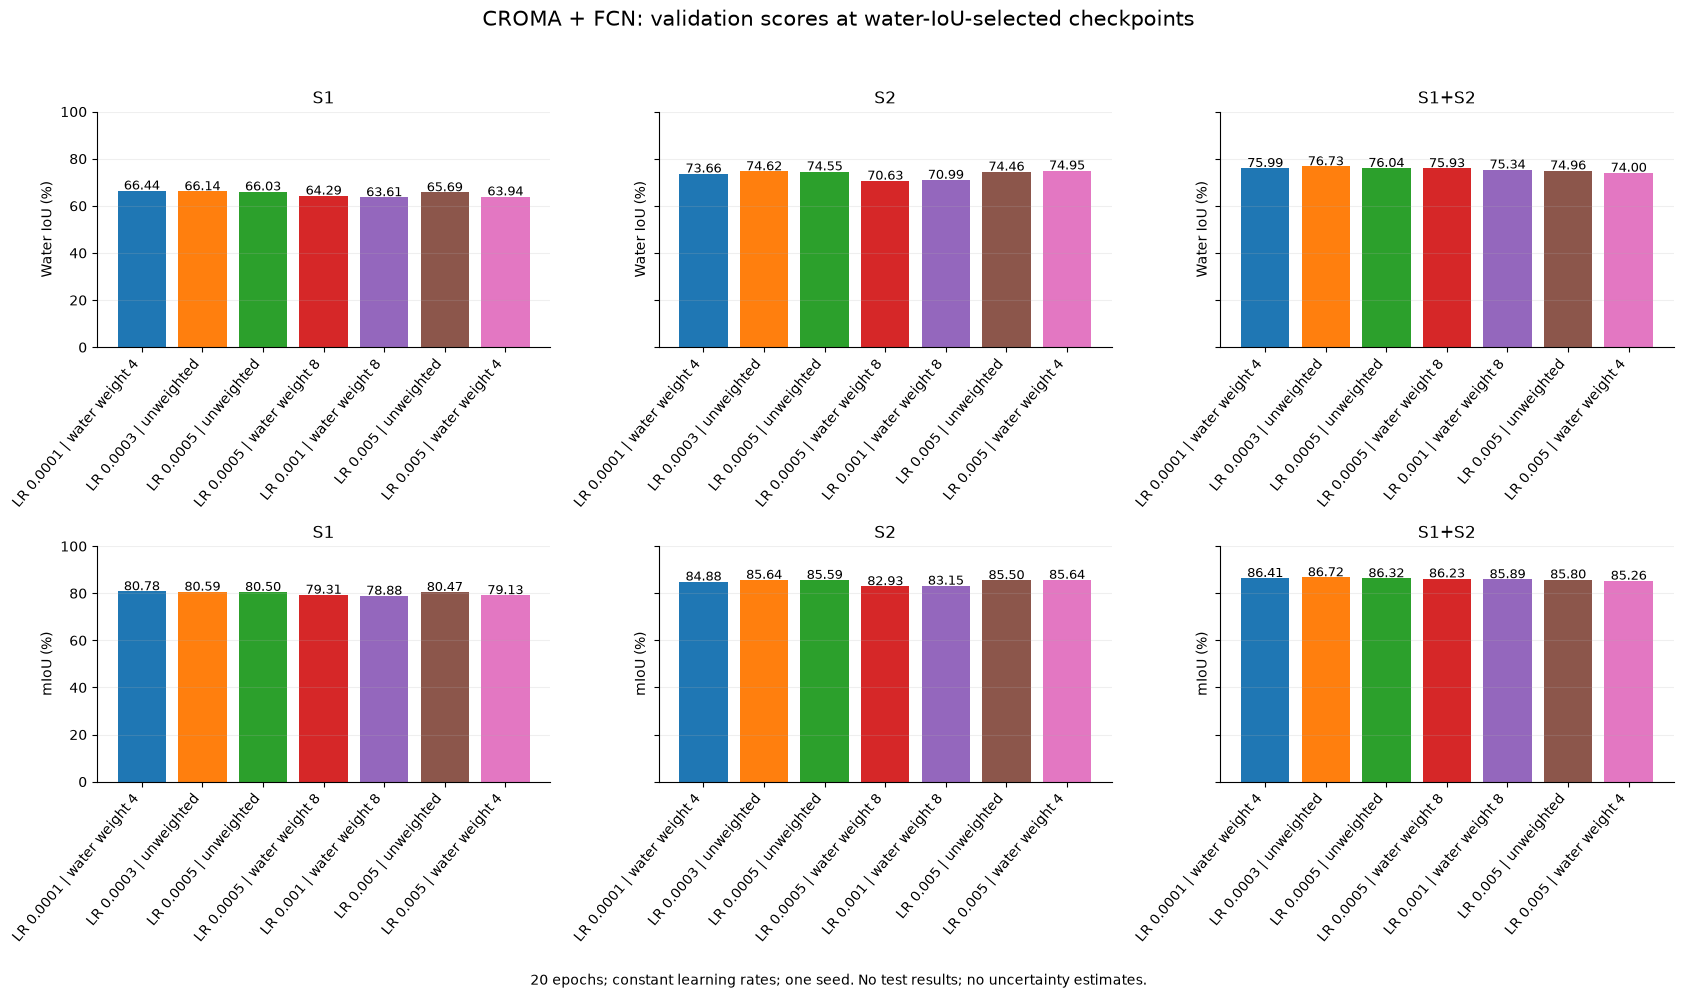

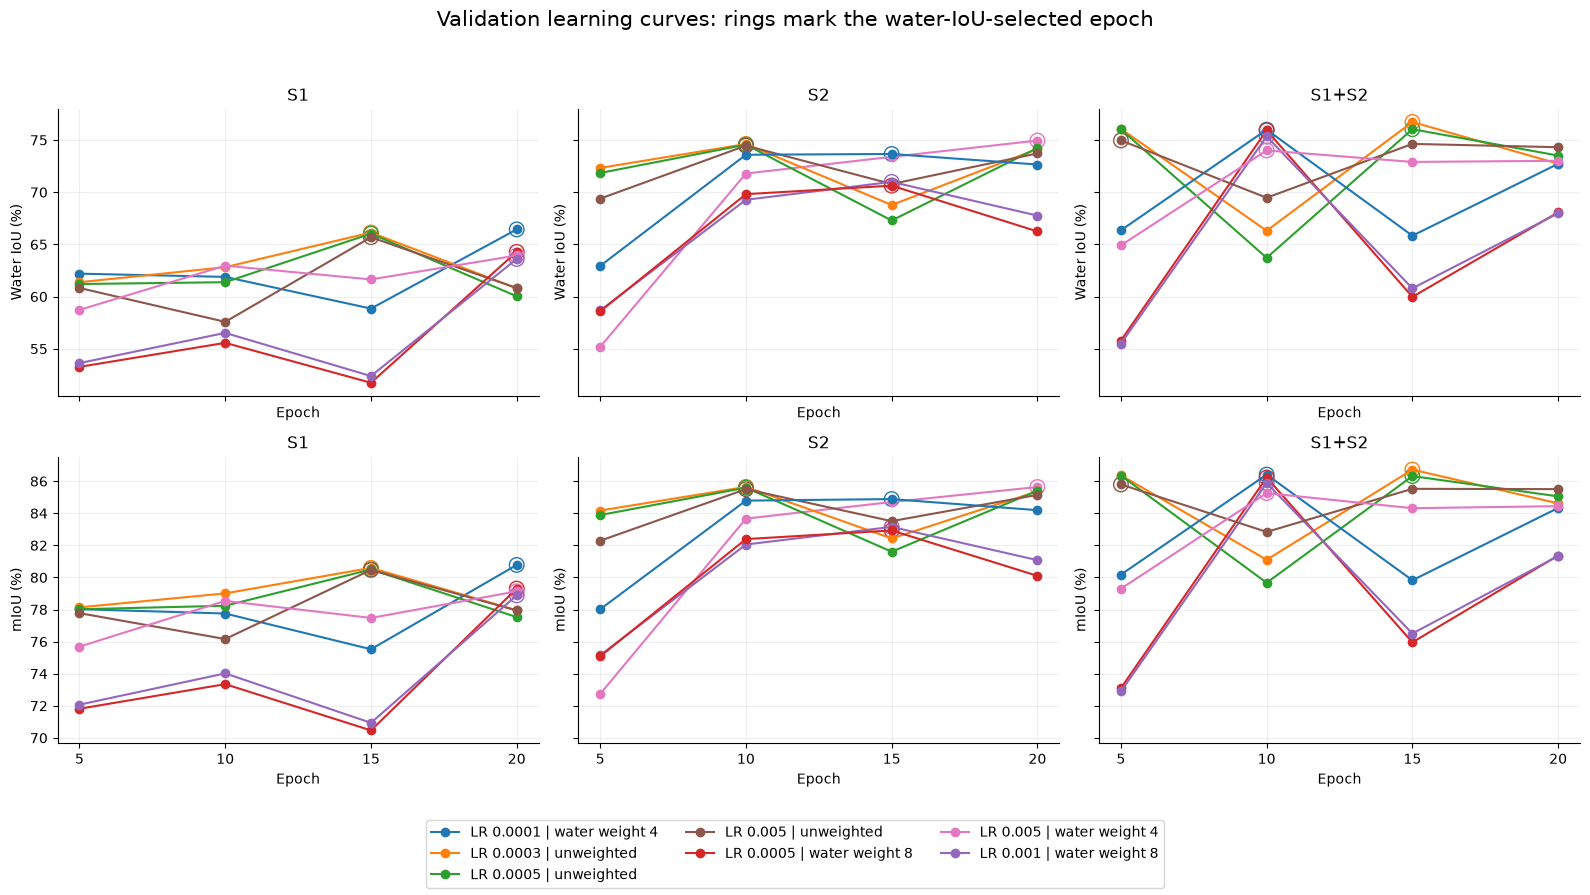

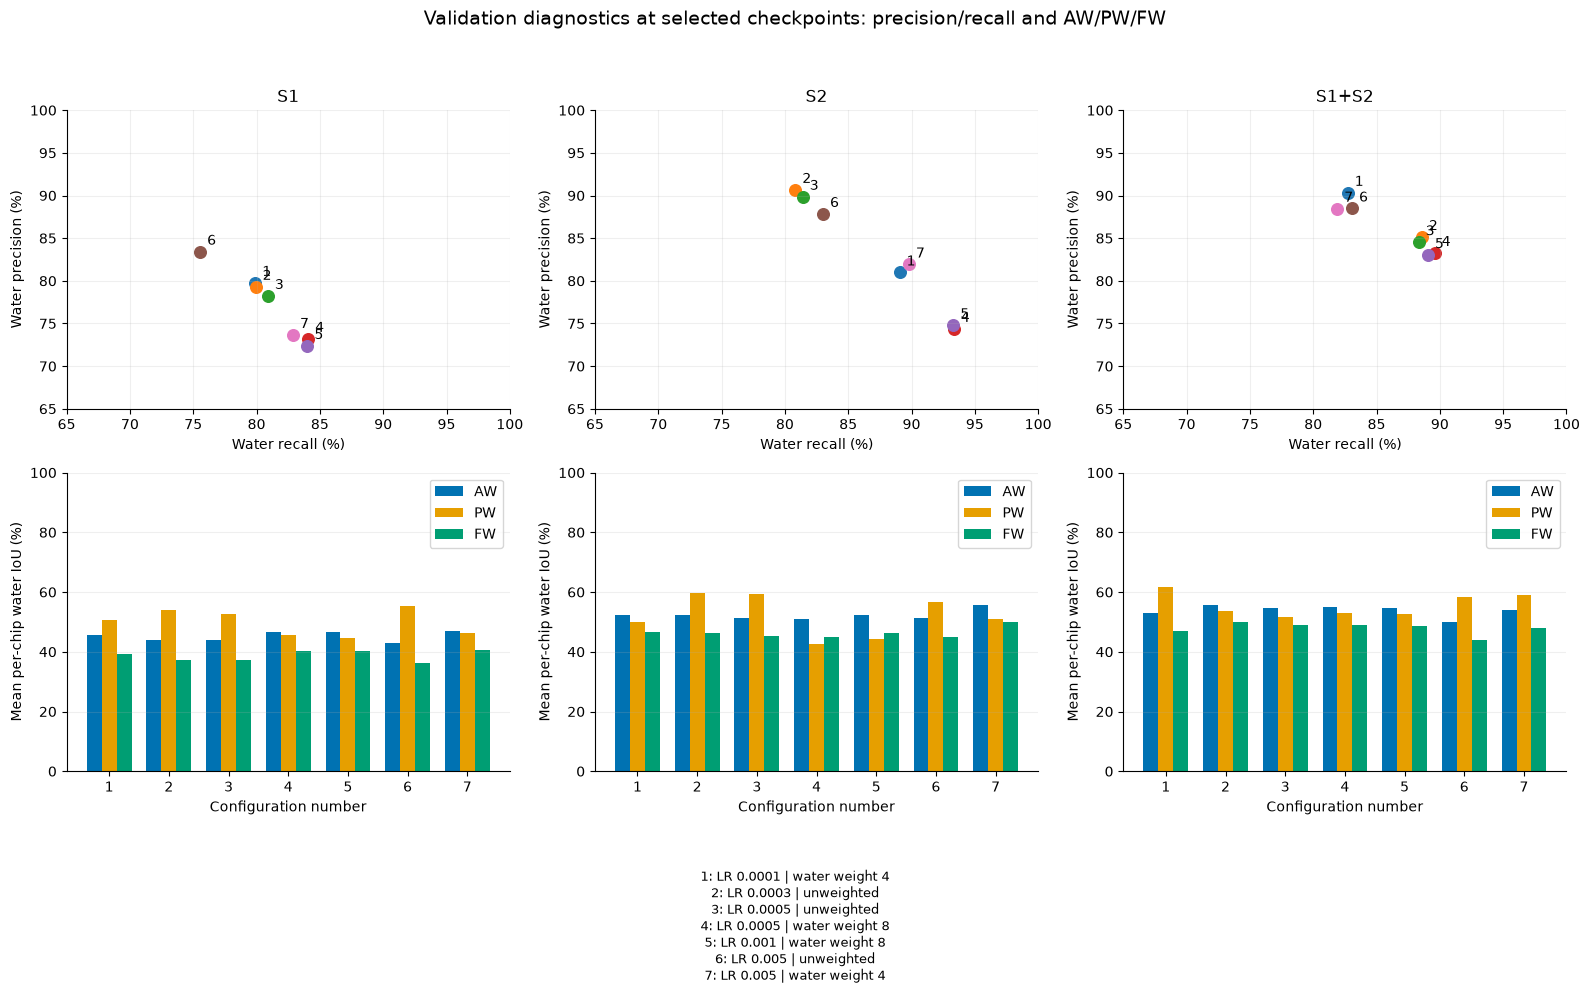

S1: LR 0.0001 | water weight 4; epoch 20; water IoU 66.44%; mIoU 80.78%
S2: LR 0.005 | water weight 4; epoch 20; water IoU 74.95%; mIoU 85.64%
S1+S2: LR 0.0003 | unweighted; epoch 15; water IoU 76.73%; mIoU 86.72%
Figures saved to reports\croma_tuning


In [8]:
# Plot saved validation results only. Run this cell alone; no training required.
# Metrics below refer to the checkpoint selected by validation water IoU.
import csv, json
from pathlib import Path
import os
# Locate the project from either the notebook folder or the project directory.
project_dir = next(p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'run.py').is_file() and (p / 'configs').is_dir())
os.chdir(project_dir)
import matplotlib.pyplot as plt

source=Path('runs/sen1floods11/croma/tuning/validation_ranking.csv')
figures=Path('reports/croma_tuning')
figures.mkdir(parents=True,exist_ok=True)
with source.open(newline='',encoding='utf-8') as file:
    results=list(csv.DictReader(file))
assert results, 'No completed results found.'
modalities=[('sar','S1'),('optical','S2'),('sar+optical','S1+S2')]
def key(row):
    weights=json.loads(row['water_weight']) if row['water_weight'] else None
    return float(row['learning_rate']), weights[1] if weights else 1
keys=sorted({key(row) for row in results})
def label(k):
    return f'LR {k[0]:g} | '+('unweighted' if k[1]==1 else f'water weight {k[1]:g}')
colors={k:plt.get_cmap('tab10')(i) for i,k in enumerate(keys)}
def save(fig,name):
    for extension in ['png','pdf']:
        fig.savefig(figures/f'{name}.{extension}',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close(fig)
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(2,3,figsize=(17,10),sharey='row')
for col,(modality,title) in enumerate(modalities):
    selected={key(row):row for row in results if row['modality']==modality}
    for line,(metric,ylabel) in enumerate([('validation_water_iou','Water IoU (%)'),('validation_miou','mIoU (%)')]):
        ax=axes[line,col]
        for i,k in enumerate(keys):
            if k not in selected:continue
            value=100*float(selected[k][metric])
            ax.bar(i,value,color=colors[k])
            ax.text(i,value+.5,f'{value:.2f}',ha='center',fontsize=9)
        ax.set(title=title,ylabel=ylabel,ylim=(0,100))
        ax.set_xticks(range(len(keys)),[label(k) for k in keys],rotation=50,ha='right')
        ax.grid(axis='y',alpha=.2)
fig.suptitle('CROMA + FCN: validation scores at water-IoU-selected checkpoints',fontsize=15)
fig.text(.5,.005,'20 epochs; constant learning rates; one seed. No test results; no uncertainty estimates.',ha='center')
fig.tight_layout(rect=(0,.03,1,.95))
save(fig,'validation_scores')

fig,axes=plt.subplots(2,3,figsize=(16,9),sharex=True,sharey='row')
for col,(modality,title) in enumerate(modalities):
    for row in results:
        if row['modality']!=modality:continue
        history=json.loads((Path(row['run_directory'].replace('\\','/'))/'metrics/history.json').read_text())
        history=[r for r in history if r.get('validation')]
        k=key(row)
        for line in range(2):
            values=[100*(r['validation']['iou_per_class'][1] if line==0 else r['validation']['miou']) for r in history]
            axes[line,col].plot([r['epoch'] for r in history],values,marker='o',color=colors[k],label=label(k))
            chosen=next(i for i,r in enumerate(history) if r['epoch']==int(row['epoch']))
            axes[line,col].scatter(int(row['epoch']),values[chosen],s=110,facecolors='none',edgecolors=[colors[k]])
    for line in range(2):
        axes[line,col].set(title=title,xlabel='Epoch',ylabel='Water IoU (%)' if line==0 else 'mIoU (%)',xticks=[5,10,15,20])
        axes[line,col].grid(alpha=.2)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=3)
fig.suptitle('Validation learning curves: rings mark the water-IoU-selected epoch',fontsize=15)
fig.tight_layout(rect=(0,.1,1,.95))
save(fig,'validation_learning_curves')

fig,axes=plt.subplots(2,3,figsize=(16,10))
for col,(modality,title) in enumerate(modalities):
    selected={key(row):row for row in results if row['modality']==modality}
    for i,k in enumerate(keys):
        if k not in selected:continue
        row=selected[k];x=100*float(row['water_recall']);y=100*float(row['water_precision'])
        axes[0,col].scatter(x,y,color=colors[k],s=70)
        axes[0,col].annotate(str(i+1),(x,y),xytext=(5,5),textcoords='offset points')
    axes[0,col].set(title=title,xlabel='Water recall (%)',ylabel='Water precision (%)',xlim=(65,100),ylim=(65,100))
    axes[0,col].grid(alpha=.2)
    for offset,(category,color) in enumerate([('AW','#0072B2'),('PW','#E69F00'),('FW','#009E73')]):
        for i,k in enumerate(keys):
            if k in selected:
                axes[1,col].bar(i+(offset-1)*.25,100*float(selected[k][category+'_mean_chip_iou']),width=.25,color=color,label=category if i==0 else None)
    axes[1,col].set(xticks=range(len(keys)),xticklabels=[str(i+1) for i in range(len(keys))],xlabel='Configuration number',ylabel='Mean per-chip water IoU (%)',ylim=(0,100))
    axes[1,col].legend()
    axes[1,col].grid(axis='y',alpha=.2)
fig.suptitle('Validation diagnostics at selected checkpoints: precision/recall and AW/PW/FW',fontsize=14)
fig.text(.5,.01,'\n'.join(f'{i+1}: {label(k)}' for i,k in enumerate(keys)),ha='center',fontsize=9)
fig.tight_layout(rect=(0,.16,1,.95))
save(fig,'validation_diagnostics')
for modality,title in modalities:
    best=max((r for r in results if r['modality']==modality),key=lambda r:float(r['validation_water_iou']))
    print(f"{title}: {label(key(best))}; epoch {best['epoch']}; water IoU {100*float(best['validation_water_iou']):.2f}%; mIoU {100*float(best['validation_miou']):.2f}%")
print('Figures saved to',figures)
